# 01 · Entendimento do Negócio e dos Dados
**WishLens: Point. Snap. Discover.** · Projeto final de Ciência de Dados I (Turma 12) · Fases 1 e 2 do CRISP-DM

> **Dados:** enquanto a turma não joga, os notebooks usam `data/processed/capturas_demo.csv` (fictício, gerado por `python -m src.exemplo`). Para usar os dados reais, baixe o CSV na página **Avaliação** do app e salve como `data/processed/avaliacao_juizes.csv`: os notebooks passam a ler esse arquivo sozinhos. As conclusões abaixo só valem de verdade com os dados reais.

## 1. Entendimento do negócio
O WishLens é um jogo de fotos do mundo real: a pessoa anda pela cidade, vê no mapa onde há coisas de cada tema (🚗 carros, 🌿 plantas e flores, 🐦 pássaros, 🐶 cachorros e gatos, 🖥️ peças e periféricos de computador) e fotografa o que encontra. Dois modelos julgam toda foto: a **IA open source** (Qwen2.5-VL ou Mistral Small, Apache 2.0: tema, achado e se a foto é real) e o **CLIP** da OpenAI (tema e chance de ser foto de tela).

**Perguntas do negócio**
1. Os juízes acertam? Com que frequência o CLIP concorda com a IA, e em quais temas eles mais discordam?
2. O jogo barra a trapaça (foto de tela, foto repetida) sem barrar quem joga certo?
3. Que estilos de jogador existem (quem caça carros, quem prefere natureza...)?
4. O que as pessoas mais encontram, quando e o quanto o tema do dia muda o comportamento?

**Critério de sucesso:** concordância CLIP × IA acima de 80%, menos de 10% de recusas contestadas e grupos de jogadores com silhueta acima de 0,25.

## 2. Entendimento dos dados
Cada linha é uma foto do jogo. O significado de cada coluna está em [docs/DICIONARIO_DE_DADOS.md](../docs/DICIONARIO_DE_DADOS.md). O CSV já vem anonimizado (`src/exportar.anonimizar`): pessoa vira `u01`, hora arredondada, só a cidade, sem hash nem célula.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.temas import POR_ID, TEMAS

sns.set_theme(style="whitegrid")
# Dados reais (CSV baixado da página Avaliação) quando existirem; senão, os fictícios de src/exemplo.py
REAL = RAIZ / "data" / "processed" / "avaliacao_juizes.csv"
DEMO = RAIZ / "data" / "processed" / "capturas_demo.csv"
ARQUIVO = REAL if REAL.exists() else DEMO
df = pd.read_csv(ARQUIVO, parse_dates=["criado_em"])
NOME_TEMA = {t.id: t.nome for t in TEMAS} | {"nenhum": "nenhum"}
print("Arquivo:", ARQUIVO.name, "| DADOS FICTÍCIOS" if ARQUIVO == DEMO else "| dados reais")
print(df.shape)

Arquivo: capturas_demo.csv | DADOS FICTÍCIOS
(198, 21)


In [2]:
df.head()

,usuario,criado_em,cidade,tema,achado,confianca,foto_real,juiz,clip_tema,clip_foto_real,...,clip_prob_tela,clip_rank_tema,contestada,aceita,motivo,do_dia,base,novidade,raridade,pontos
0,u01,2026-10-29 19:00:00,Vitória - ES,passaros,sabiá-laranjeira,0.61,True,ia+clip,passaros,True,...,0.146,1.0,NaN,True,NaN,False,10,10,20,40
1,u01,2026-10-29 20:00:00,Vitória - ES,plantas,espada-de-são-jorge,0.61,True,ia+clip,plantas,True,...,0.001,1.0,NaN,True,NaN,False,10,10,20,40
2,u01,2026-10-30 19:00:00,Vitória - ES,passaros,gavião-carijó,0.94,True,ia+clip,passaros,True,...,0.044,1.0,NaN,True,NaN,False,10,10,20,40
3,u01,2026-10-30 22:00:00,Vitória - ES,passaros,gavião-carijó,0.59,True,ia+clip,passaros,True,...,0.158,1.0,NaN,False,você já achou isso hoje,False,0,0,0,0
4,u01,2026-10-31 16:00:00,Vitória - ES,plantas,bromélia,0.94,True,ia+clip,plantas,True,...,0.160,1.0,NaN,True,NaN,False,10,10,20,40


In [3]:
df.dtypes

usuario                      str
criado_em         datetime64[us]
cidade                       str
tema                         str
achado                       str
confianca                float64
foto_real                   bool
juiz                         str
clip_tema                    str
clip_foto_real              bool
clip_prob_tema           float64
clip_prob_tela           float64
clip_rank_tema           float64
contestada                   str
aceita                      bool
motivo                       str
do_dia                      bool
base                       int64
novidade                   int64
raridade                   int64
pontos                     int64
dtype: object

### Estatísticas descritivas

In [4]:
df.describe(include="number").round(3)

,confianca,clip_prob_tema,clip_prob_tela,clip_rank_tema,base,novidade,raridade,pontos
count,198.000,190.000,198.000,190.000,198.000,198.000,198.000,198.000
mean,0.734,0.552,0.122,1.374,7.727,4.646,7.621,24.798
std,0.157,0.235,0.134,0.966,4.201,5.000,7.081,20.696
min,0.300,0.025,0.000,1.000,0.000,0.000,0.000,0.000
25%,0.610,0.420,0.042,1.000,10.000,0.000,2.000,12.000
50%,0.730,0.579,0.104,1.000,10.000,0.000,5.000,24.000
75%,0.867,0.754,0.158,1.000,10.000,10.000,10.000,40.000
max,0.970,0.895,0.774,5.000,10.000,10.000,20.000,80.000


In [5]:
df.select_dtypes(exclude="number").astype("string").describe()

,usuario,criado_em,cidade,tema,achado,foto_real,juiz,clip_tema,clip_foto_real,contestada,aceita,motivo,do_dia
count,198,198,198,198,190,198,198,190,198,8,198,45,198
unique,9,124,1,6,41,2,1,5,2,4,2,17,2
top,u04,2026-11-10 20:00:00,Vitória - ES,carros,teclado mecânico,True,ia+clip,carros,True,carros,True,"não é foto real (tela, impressão ou desenho)",False
freq,30,5,198,66,13,189,198,64,189,4,153,9,155


### Valores ausentes
Nulos esperados: `achado` vazio quando o tema é *nenhum*; `motivo` só nas recusas; `contestada` só quando a pessoa contestou; colunas `clip_*` vazias quando o CLIP não julgou.

In [6]:
df.isna().sum().to_frame("nulos").assign(pct=lambda t: (t.nulos / len(df) * 100).round(1))

,nulos,pct
usuario,0,0.0
criado_em,0,0.0
cidade,0,0.0
tema,0,0.0
achado,8,4.0
confianca,0,0.0
foto_real,0,0.0
juiz,0,0.0
clip_tema,8,4.0
clip_foto_real,0,0.0


### Fotos por tema e por juiz

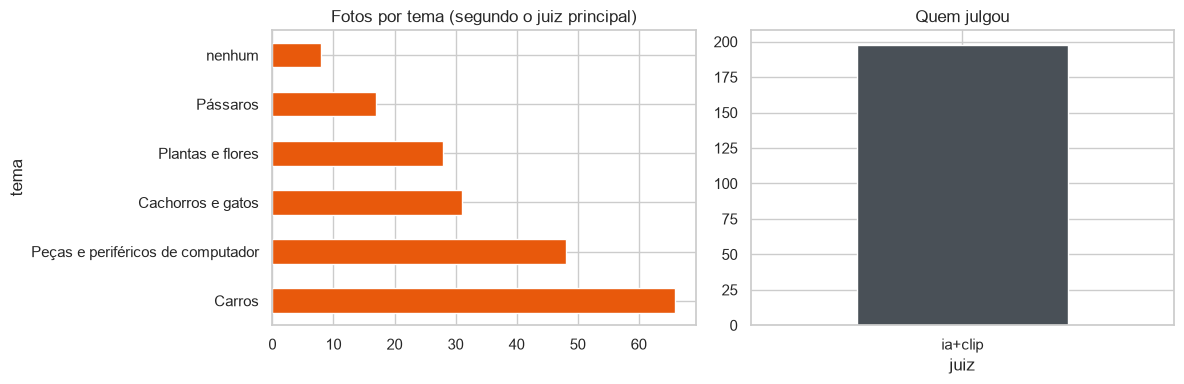

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["tema"].map(NOME_TEMA).value_counts().plot.barh(ax=ax[0], color="#e8590c")
ax[0].set_title("Fotos por tema (segundo o juiz principal)")
df["juiz"].value_counts().plot.bar(ax=ax[1], color="#495057", rot=0)
ax[1].set_title("Quem julgou")
plt.tight_layout()

### Aceitas × recusadas

In [8]:
print(f"Aceitas: {df['aceita'].mean():.0%} de {len(df)} fotos")
df.loc[~df["aceita"], "motivo"].str.replace(r" \(.*\)$", "", regex=True).value_counts()

Aceitas: 77% de 198 fotos


motivo
os juízes discordaram do tema    23
não é foto real                   9
não é de nenhum tema do jogo      8
você já achou isso hoje           5
Name: count, dtype: int64

### Quando as pessoas jogam

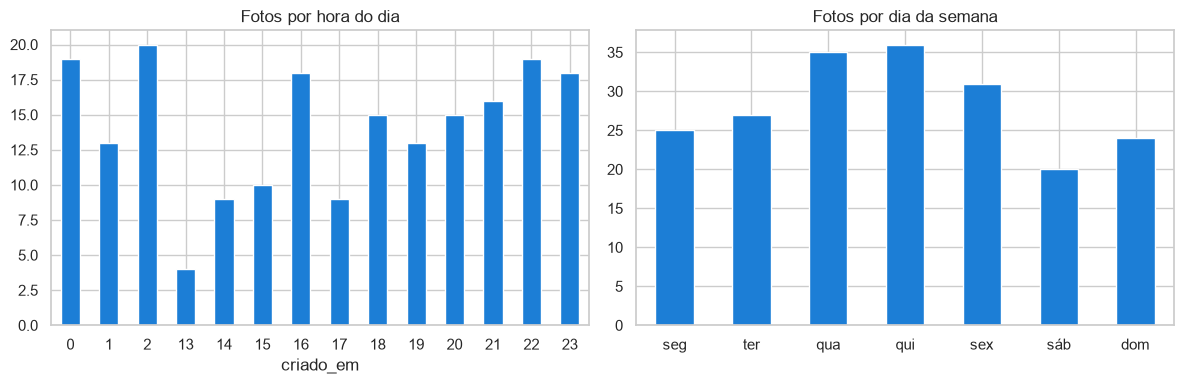

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["criado_em"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], color="#1c7ed6", rot=0)
ax[0].set_title("Fotos por hora do dia")
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
df["criado_em"].dt.day_of_week.value_counts().reindex(range(7), fill_value=0).set_axis(dias).plot.bar(ax=ax[1], color="#1c7ed6", rot=0)
ax[1].set_title("Fotos por dia da semana")
plt.tight_layout()

### O que mais se encontra

In [10]:
aceitas = df[df["aceita"]]
aceitas.groupby("tema")["achado"].agg(lambda s: ", ".join(s.value_counts().head(3).index)).rename(index=NOME_TEMA).to_frame("3 achados mais comuns")

,3 achados mais comuns
tema,
Carros,"Chevrolet Onix, Hyundai HB20, Fiat Mobi"
Pássaros,"pombo, bem-te-vi, sabiá-laranjeira"
Peças e periféricos de computador,"teclado mecânico, mouse, processador"
Cachorros e gatos,"cachorro shih-tzu, gato siamês, cachorro vira-..."
Plantas e flores,"hibisco, espada-de-são-jorge, costela-de-adão"


### Distribuição dos pontos

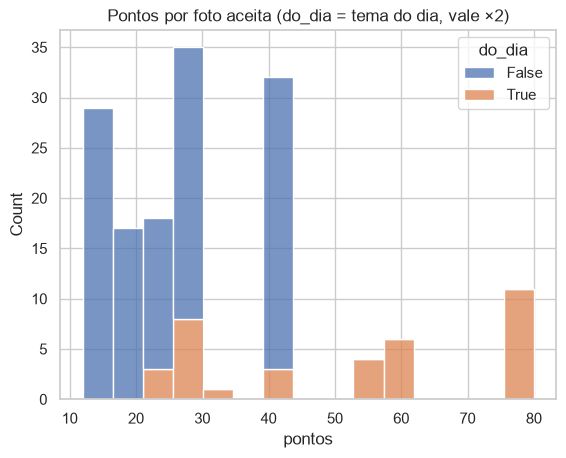

In [11]:
sns.histplot(aceitas, x="pontos", hue="do_dia", bins=15, multiple="stack")
plt.title("Pontos por foto aceita (do_dia = tema do dia, vale ×2)");

### Limitações dos dados
- Amostra pequena (uma turma) e de uma só cidade: não generaliza para outras regiões.
- O **tema** e o **achado** vêm do próprio juiz: não há um rótulo verdadeiro independente. As contestações são o único sinal de erro vindo das pessoas.
- Quem joga mais pesa mais nas contagens; por isso o perfil (notebook 02) usa proporções por pessoa.
- Privacidade (LGPD): a foto não é guardada, só o hash, e o CSV não tem bairro nem célula.